# Record repair and a frozen push screen: knob table and push-movability screen (demo)

**Artifact `art_sV0cQ3ef1ZRQ`** (evaluation) is the CPU-only Step 0 of iteration 4 of a study on *algorithm choice* in Qwen3-8B, with Llama-3.1-8B as the replication model. The study asks how "creativity" shows up, meaning a program written with a different algorithm than the model's default, and which knob actually moves it. The candidates are temperature, context seeds, instructions ("make a fully novel algorithm…"), prompt bans, token vetoes and directions added in activation space.

This step generates no model text. It recomputes every number from **labelled program rows** of 11 earlier experiments. Each program is labelled with:
- the algorithm it implements;
- whether it passed the hidden tests;
- whether that algorithm is in the task's catalogue of known algorithms;
- whether it is the model's default.

The original entry point `eval.py` runs 14 stages from `src/`. This notebook runs the two central ones on a curated subset, with the original code split into cells. Every change is marked `NOTEBOOK:`.

| Stage | What it computes |
|---|---|
| `knob` | The **one-statistic knob table**. For every artifact × task × arm × dial cell: the correct-only **rarefied Hill-1 at depth 25** (`H1r25`, the effective number of distinct algorithms among 25 correct programs) with 90% bootstrap CIs, Good's coverage, the **pass cost** against the cell's own twin (Newcombe 95% CI), the off-default share, the catalogue-only avoidance, and the escape and qualify flags. |
| `screen` | The **frozen push-movability screen**. A random activation direction *escapes* if it raises the off-default share by at least 0.20 over its twin while keeping pass ≥ 0.8 × twin. A task is *movable* if any direction escapes at α ≤ 2. The screen rule says *movable ⇒ catalogue-only modal-ban avoidance ≥ 0.5*. |

**Demo data** (`mini_demo_data.json`) holds 99 of the 1,120 knob-table cells and the 6,925 labelled program rows behind them, in two parts:
- the complete screen input of tasks T10, T13, T14, T03 and T1;
- every kind of knob the study tried on the path-search task **T1**, "implement a path search algorithm", which asks whether the model always writes BFS.

Each cell carries its recorded values, so every recomputed number is checked against the artifact.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, scipy, matplotlib, pyarrow — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pyarrow==18.1.0')

In [2]:
from __future__ import annotations

# --- original imports (eval.py, src/stages.py, src/stats.py, src/labels.py, src/knob.py, src/screen.py, screen_rule.py) ---
import argparse
import hashlib
import importlib.util
import itertools
import json
import math
import multiprocessing as mp
import re
import resource
import sys
import time
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from functools import lru_cache
from pathlib import Path
from typing import Any, Iterable, Sequence

import numpy as np
import pandas as pd
from loguru import logger
from scipy import stats as sps

# --- notebook additions: a namespace standing in for the screen_rule.py module, tables and figures ---
import types

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-4/evaluation-3/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(examples)} cells, "
      f"{sum(len(e['metadata_programs']['label_norm']) for e in examples)} labelled program rows")
for g in data["metadata"]["groups"]:
    print(f"  {g['group']:<11} {g['n_cells']:>3} cells  {g['note']}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'knob_table': 99 cells, 6925 labelled program rows
  screen:T10    6 cells  connected components: exp13 bf16 random directions rand1-3, their HF twin, the modal ban and its vLLM twin
  screen:T13    6 cells  merge intervals (immovable): exp13 random directions, HF twin, modal ban and vLLM twin
  screen:T14    6 cells  top-k frequent (immovable; modal ban Hill 1.78 at 17 pts): exp13 random directions, twins, modal ban
  screen:T03   25 cells  k-th smallest: exp13 rand1-3 + exp17 RAND90xx directions at alpha 1 and 2, both twins, the modal ban
  screen:T1    21 cells  path search: exp17 RAND90xx directions at alpha 1 and 2 and their twin; exp9 single BFS ban and its baseline
  knobs:T1     32 cells  path search: temperature x sampler grid, context seeds, creativity instructions, generate-then-select, top-k / list bans, decommitment and random steering, token vetoes, 2,000-word novelty instruction
 

## Configuration

All tunable parameters are set here; re-run the notebook from this cell after changing them.
- `N_RAREFY`, `N_BOOT` and `N_BOOT_RAREFY` are the Monte-Carlo sizes of `src/stats.py`. With the original values (1000 / 1000 / 200) and the original per-cell seeds, every Hill-1 value and CI is recomputed exactly. Smaller values run faster and give Hill-1 values within Monte-Carlo error of the recorded ones.
- Pass rates, pass costs, coverage, avoidance shares and the screen itself are exact at any setting, because they are counts.
- `N_CELLS` takes the first cells of the demo data. The cells are ordered in groups, with each twin before the cells priced against it, so any prefix of at least 6 cells is self-consistent.

In [5]:
# ---- tunable parameters (the original values are in the comments) ----
# Monte-Carlo sizes of src/stats.py (original: N_RAREFY = 1000, N_BOOT = 1000, N_BOOT_RAREFY = 200)
N_RAREFY = 1000      # rarefaction subsamples per Hill-1 value
N_BOOT = 1000        # bootstrap replicates per 90% CI
N_BOOT_RAREFY = 200  # rarefaction subsamples inside each bootstrap replicate
# data size (original: all 1,120 cells of data/rows.parquet; mini_demo_data.json holds 99 of them)
N_CELLS = 99         # first N demo cells, at least 6 (the first 6 are the complete T10 screen group); 99 = all
# eval.py --stages (original default: all 14 stages; only these two run from the demo data)
RUN_STAGES = ["knob", "screen"]
# output folder (the original wrote into the artifact folder: data/, tables/, results/, screen.json, logs/)
WS = Path("demo_run")

## `eval.py` entry point: logging, stage list, memory cap

`eval.py` is a single entry point with stage flags (`uv run eval.py --stages all`). Each stage reads earlier stages' outputs from `data/` and `results/`. The cell below holds its logger setup, the stage list and the address-space cap, plus the output folders that `src/stages.py` creates.

Of the 14 stages, only `knob` and `screen` are defined in this notebook. The other twelve read files of the 11 dependency artifacts or the LLM-judge cache, which the demo data does not ship: `inventory`, `rows`, `judges`, `route`, `llama`, `other`, `figures`, `rigor`, `wording`, `rivals`, `audit` and `outputs`.

In [6]:
# eval.py: "Iteration-4 Step 0: record repair and frozen push screen. Single entry point with stage flags."
# NOTEBOOK: WS was Path(__file__).resolve().parent (the artifact folder); here it is the config cell's output folder
WS.mkdir(exist_ok=True)

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(WS / "logs" / "eval.log", rotation="30 MB", level="DEBUG")

STAGES = ["inventory", "rows", "judges", "knob", "screen", "route", "llama", "other", "figures", "rigor", "wording", "rivals",
          "audit", "outputs"]


def _limit_memory(gb: float = 18.0) -> None:
    try:
        resource.setrlimit(resource.RLIMIT_AS, (int(gb * 1024 ** 3), int(gb * 1024 ** 3)))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


# src/stages.py: "Stage implementations called by eval.py. Each stage reads earlier stages' outputs from data/ and results/."
DATA = WS / "data"
RES = WS / "results"
TAB = WS / "tables"
for _d in (DATA, RES, TAB, WS / "figures", WS / "audit"):
    _d.mkdir(exist_ok=True)

## Artifact ids and label catalogues (`src/paths.py`, `src/labels.py`)

Every output cites its source as `<artifact_id>:<relative path>`. `ARTIFACTS` maps the 11 dependency artifacts to their short experiment names, exp4 to exp18.

`src/labels.py` (step G1) holds the task lists, each task's **catalogue** of known algorithms, and the model's **default** algorithm. For T1, path search, the default is BFS.
- The bench catalogues come from exp11's `bench/<task>/spec.json`. The demo data carries those of the screened bench tasks, so `spec()` reads them from `data` instead of the file system.
- Two kinds of code are left out because the demo rows are already normalised: the functions that locate dependency folders on disk (`root`, `p`), and the label-normalisation helpers that only the `rows` stage uses.

In [7]:
# ---- src/paths.py: artifact id -> short experiment name; '<artifact_id>:<relative path>' citations ----
# artifact id -> (root env var, workspace folder, short experiment name)
ARTIFACTS: dict[str, tuple[str, str, str]] = {
    "art_U5UKkFrOgSsE": ("AII_ITER1", "gen_art_experiment_4", "exp4"),
    "art_UoCVh2Qe5RZ0": ("AII_ITER1", "gen_art_experiment_6", "exp6"),
    "art_6zBfl3kDjeiP": ("AII_ITER2", "gen_art_experiment_7", "exp7"),
    "art_IVZc3TWCeE9f": ("AII_ITER2", "gen_art_experiment_9", "exp9"),
    "art_0ndRfWKBWclR": ("AII_ITER2", "gen_art_experiment_11", "exp11"),
    "art_1AYTO1Epb_7t": ("AII_ITER3", "gen_art_experiment_13", "exp13"),
    "art_WiY4wqHLb9Gy": ("AII_ITER3", "gen_art_experiment_14", "exp14"),
    "art_Q-qh-9HhPoWo": ("AII_ITER3", "gen_art_experiment_15", "exp15"),
    "art__5akZ9W9iZM4": ("AII_ITER3", "gen_art_experiment_16", "exp16"),
    "art_pVlCZ272hDV7": ("AII_ITER3", "gen_art_experiment_17", "exp17"),
    "art_ccAbfJVcv0LO": ("AII_ITER3", "gen_art_experiment_18", "exp18"),
}
BY_EXP = {v[2]: k for k, v in ARTIFACTS.items()}


def cite(exp_or_aid: str, rel: str) -> str:
    aid = BY_EXP.get(exp_or_aid, exp_or_aid)
    return f"{aid}:{rel}"


def exp_name(aid: str) -> str:
    return ARTIFACTS[aid][2]


# ---- src/labels.py (STEP G1): task lists, catalogues, defaults ----
BENCH_DIRS = {
    "T03": "T03_kth_smallest", "T04": "T04_substring_search", "T05": "T05_two_sum", "T06": "T06_find_duplicate",
    "T08": "T08_fibonacci", "T10": "T10_connected_components", "T11": "T11_longest_increasing_subsequence",
    "T13": "T13_merge_intervals", "T14": "T14_top_k_frequent", "R1": "R1_non_overlapping_intervals",
    "R2": "R2_cycle_detection", "R3": "R3_topological_order", "R6": "R6_first_last_position",
}
BENCH12 = ["T03", "T04", "T05", "T06", "T08", "T10", "T11", "T13", "T14", "R1", "R3", "R6"]
PATH_TASKS = ["T1", "T2"]
QWEN14 = BENCH12 + PATH_TASKS

T1_CATALOGUE = ["bfs", "dfs", "bibfs", "iddfs", "astar", "gbfs", "idastar", "dijkstra_unit"]
T2_CATALOGUE = ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]

QWEN_DEFAULT = {
    "T03": "full_sort", "T04": "naive", "T05": "hash_map", "T06": "hash_set", "T08": "iteration", "T10": "union_find",
    "T11": "quadratic_dp", "T13": "sort_sweep", "T14": "sort_by_count", "R1": "greedy_end", "R3": "kahn",
    "R6": "binary_search", "T1": "bfs", "T2": "dijkstra",
}


@lru_cache(maxsize=None)
def spec(task: str) -> dict:
    # NOTEBOOK: was json.loads(p("exp11", f"bench/{BENCH_DIRS[task]}/spec.json").read_text()); the demo data carries the
    # catalogues of the screened bench tasks
    return data["metadata"]["task_specs"][task]


@lru_cache(maxsize=None)
def catalogue(task: str) -> tuple[str, ...]:
    if task == "T1":
        return tuple(T1_CATALOGUE)
    if task == "T2":
        return tuple(T2_CATALOGUE)
    return tuple(c["mode"] for c in spec(task)["catalogue"])


def default_of(task: str, model: str = "qwen") -> str | None:
    # NOTEBOOK: the Llama branch reads exp15 results/c1_events.jsonl (llama_defaults, not shipped); every demo cell is Qwen
    if "llama" in model.lower():
        return llama_defaults().get(task)
    return QWEN_DEFAULT.get(task)


for _t in ("T1", "T03", "T10", "T13", "T14"):
    print(f"{_t}: default {default_of(_t)!r}; catalogue {list(catalogue(_t))}")

T1: default 'bfs'; catalogue ['bfs', 'dfs', 'bibfs', 'iddfs', 'astar', 'gbfs', 'idastar', 'dijkstra_unit']
T03: default 'full_sort'; catalogue ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
T10: default 'union_find'; catalogue ['bfs', 'dfs', 'union_find', 'label_propagation']
T13: default 'sort_sweep'; catalogue ['sort_sweep', 'interval_tree', 'union_find']
T14: default 'sort_by_count'; catalogue ['sort_by_count', 'heap', 'bucket_sort', 'quickselect_counts']


## Diversity statistic (`src/stats.py`, part 1)

The knob table's one statistic is **correct-only, rarefied Hill-1 at depth 25**. Take the algorithm labels of the programs that passed, draw 25 of them without replacement (`N_RAREFY` times), and average `exp(Shannon entropy)` of the label shares. The result is the effective number of distinct algorithms among 25 correct programs: 1.0 means every correct program uses the same algorithm, 2.0 means two equally common algorithms. Rarefying to a fixed depth makes cells with different numbers of correct programs comparable. Cells with fewer than 25 correct programs get no depth-25 value (`below_depth`) and report a depth-10 value instead.

`h1r_cell` also returns:
- Good's coverage, 1 − singletons / n;
- a 90% percentile CI from an iid program bootstrap (`N_BOOT` replicates × `N_BOOT_RAREFY` rarefactions). When the cell has 5 prompt templates with ≥ 5 correct programs each, a template-cluster bootstrap replaces it.

Every cell draws from its own seed, `sha256('20261021|' + cell id)`, so results do not depend on the order in which cells are processed.

In [8]:
MASTER_SEED = 20261021
DEPTH = 25
DEPTH_LOW = 10
# NOTEBOOK: N_RAREFY, N_BOOT and N_BOOT_RAREFY (originally 1000, 1000 and 200) are set in the config cell


def cell_seed(cell_id: str) -> int:
    return int(hashlib.sha256(f"{MASTER_SEED}|{cell_id}".encode()).hexdigest()[:8], 16)


def hill1_counts(x: np.ndarray) -> float:
    x = np.asarray(x, float)
    x = x[x > 0]
    if x.sum() <= 0:
        return float("nan")
    q = x / x.sum()
    return float(math.exp(-(q * np.log(q)).sum()))


def _hill1_rows(draws: np.ndarray, depth: int) -> np.ndarray:
    q = draws / depth
    with np.errstate(divide="ignore", invalid="ignore"):
        h = np.where(q > 0, q * np.log(np.where(q > 0, q, 1.0)), 0.0).sum(axis=1)
    return np.exp(-h)


def rarefied_hill1(counts: Sequence[int], depth: int, n_draws: int, rng: np.random.Generator) -> float:
    c = np.asarray([int(v) for v in counts if int(v) > 0], np.int64)
    if c.sum() < depth or len(c) == 0:
        return float("nan")
    if len(c) == 1:
        return 1.0
    if c.sum() == depth:
        return hill1_counts(c)
    d = rng.multivariate_hypergeometric(c, depth, size=n_draws, method="marginals")
    return float(_hill1_rows(d, depth).mean())


def goods_coverage(counts: Sequence[int]) -> float:
    c = np.asarray([v for v in counts if v > 0])
    n = c.sum()
    if n == 0:
        return float("nan")
    f1 = int((c == 1).sum())
    return float(1 - f1 / n)


def h1r_cell(correct_labels: Sequence[str], templates: Sequence[str] | None, cell_id: str, depth: int = DEPTH,
             drop: Iterable[str] = (), n_boot: int = N_BOOT, n_boot_rarefy: int = N_BOOT_RAREFY,
             with_ci: bool = True) -> dict:
    """Correct-only rarefied Hill-1 for one cell; percentile CIs (template-cluster when eligible, and iid)."""
    drop = set(drop)
    keep = [i for i, l in enumerate(correct_labels) if l not in drop]
    labs = [correct_labels[i] for i in keep]
    tpls = [templates[i] for i in keep] if templates is not None else None
    cats = sorted(set(labs))
    idx = {c: i for i, c in enumerate(cats)}
    counts = np.zeros(len(cats), np.int64)
    for l in labs:
        counts[idx[l]] += 1
    n_c = int(counts.sum())
    rng = np.random.default_rng(cell_seed(f"{cell_id}|d{depth}|{'-'.join(sorted(drop))}"))
    out = {"n_c": n_c, "S_obs": int((counts > 0).sum()), "coverage": goods_coverage(counts),
           "value": rarefied_hill1(counts, depth, N_RAREFY, rng), "ci90": [float("nan")] * 2,
           "ci90_iid": [float("nan")] * 2, "ci_unit": None}
    if not with_ci or n_c < depth or len(cats) <= 1:
        if n_c >= depth and len(cats) == 1:
            out["ci90"] = [1.0, 1.0]
            out["ci90_iid"] = [1.0, 1.0]
            out["ci_unit"] = "degenerate"
        return out
    # iid program bootstrap
    probs = counts / n_c
    vals = np.full(n_boot, np.nan)
    for b in range(n_boot):
        cb = rng.multinomial(n_c, probs)
        vals[b] = rarefied_hill1(cb, depth, n_boot_rarefy, rng)
    out["ci90_iid"] = [float(np.nanquantile(vals, 0.05)), float(np.nanquantile(vals, 0.95))]
    out["ci90"] = list(out["ci90_iid"])
    out["ci_unit"] = "program"
    if tpls is not None:
        by_t: dict[str, np.ndarray] = {}
        for l, t in zip(labs, tpls):
            by_t.setdefault(str(t), np.zeros(len(cats), np.int64))[idx[l]] += 1
        tkeys = sorted(by_t)
        if len(tkeys) == 5 and all(by_t[t].sum() >= 5 for t in tkeys):
            mat = np.stack([by_t[t] for t in tkeys])
            tv = np.full(n_boot, np.nan)
            for b in range(n_boot):
                pick = rng.integers(0, len(tkeys), len(tkeys))
                tv[b] = rarefied_hill1(mat[pick].sum(0), depth, n_boot_rarefy, rng)
            if np.isfinite(tv).sum() > 0.5 * n_boot:
                out["ci90"] = [float(np.nanquantile(tv, 0.05)), float(np.nanquantile(tv, 0.95))]
                out["ci_unit"] = "template(5 clusters; few-cluster)"
    return out

## Pass cost and screen statistics (`src/stats.py`, part 2)

A knob only matters if the programs still work.
- **Pass cost** = 100 × (twin pass rate − arm pass rate), in percentage points. Its 95% interval is the Newcombe (1998, method 10) hybrid-score interval built from two Wilson intervals.
- The screen summary uses a one-sided Fisher exact test and the balanced accuracy of *movable* against *avoidance ≥ 0.5*.
- The power note `1 − 0.1^(1/K)` is the one-sided 90% upper bound on a task's per-direction escape probability when 0 of K directions escape.

The other functions in `src/stats.py`, such as the permutation Spearman, Poisson-binomial, kappa and jackknife, serve stages outside this demo.

In [9]:
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n <= 0:
        return float("nan"), float("nan")
    ph = k / n
    den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe_diff(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float, float]:
    """p1 - p2 with the Newcombe (1998, method 10) hybrid-score 95% interval."""
    if n1 <= 0 or n2 <= 0:
        return float("nan"), float("nan"), float("nan")
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return d, d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


def balanced_accuracy(pred: Sequence[int], truth: Sequence[int]) -> float:
    pred, truth = np.asarray(pred), np.asarray(truth)
    pos, neg = truth == 1, truth == 0
    if pos.sum() == 0 or neg.sum() == 0:
        return float("nan")
    return float(0.5 * ((pred[pos] == 1).mean() + (pred[neg] == 0).mean()))


def fisher_2x2(pred: Sequence[int], truth: Sequence[int], alternative: str = "two-sided") -> dict:
    pred, truth = np.asarray(pred), np.asarray(truth)
    tab = [[int(((pred == 1) & (truth == 1)).sum()), int(((pred == 1) & (truth == 0)).sum())],
           [int(((pred == 0) & (truth == 1)).sum()), int(((pred == 0) & (truth == 0)).sum())]]
    res = sps.fisher_exact(tab, alternative=alternative)
    return {"table": tab, "p": float(res.pvalue), "alternative": alternative}


def upper_bound_zero_of_k(k: int, level: float = 0.90) -> float:
    """One-sided upper bound on a per-direction escape probability when 0 of k escape."""
    return float(1 - (1 - level) ** (1 / k)) if k > 0 else float("nan")

## Labelled program rows (replaces the `rows` stage and `data/rows.parquet`)

In the original pipeline, the `rows` stage (step G2) merges the labelled samples of the 11 dependencies into `data/rows.parquet`, 65,433 rows in all, one per generated program. Each row gives:
- the program's cell: artifact, task, arm, dial and precision;
- its prompt template and normalised algorithm label;
- the flags `attempted` (the output contains a program), `passed` (it passed the hidden tests), `is_catalogue` and `is_default`.

Here the same columns are rebuilt from the demo cells.

In [10]:
def rows_from_data(data: dict, n_cells: int) -> pd.DataFrame:
    """One row per labelled program of the first n_cells demo cells, with the data/rows.parquet columns the knob stage reads."""
    recs = []
    for ex in data["datasets"][0]["examples"][:n_cells]:
        key, prog = ex["metadata_cell_key"], ex["metadata_programs"]
        for tpl, lab, cat, dft, att, ok in zip(prog["template"], prog["label_norm"], prog["is_catalogue"], prog["is_default"],
                                               prog["attempted"], prog["passed"]):
            recs.append({**key, "src_file": prog["src_file"], "model": prog["model"], "engine": prog["engine"],
                         "template": tpl, "label_norm": lab, "is_catalogue": cat, "is_default": dft, "attempted": att,
                         "passed": ok})
    return pd.DataFrame(recs)


_rows = rows_from_data(data, N_CELLS)
print(f"{len(_rows)} labelled program rows in {_rows.groupby(['artifact_id', 'task', 'arm', 'dial', 'precision']).ngroups} cells")
display(_rows.head())

6925 labelled program rows in 99 cells


,artifact_id,task,arm,dial,precision,src_file,model,engine,template,label_norm,is_catalogue,is_default,attempted,passed
0,art_1AYTO1Epb_7t,T10,hf_twin,{},bf16,data/samples.jsonl,Qwen/Qwen3-8B,hf,W1,union_find,True,True,True,True
1,art_1AYTO1Epb_7t,T10,hf_twin,{},bf16,data/samples.jsonl,Qwen/Qwen3-8B,hf,W1,union_find,True,True,True,True
2,art_1AYTO1Epb_7t,T10,hf_twin,{},bf16,data/samples.jsonl,Qwen/Qwen3-8B,hf,W1,union_find,True,True,True,True
3,art_1AYTO1Epb_7t,T10,hf_twin,{},bf16,data/samples.jsonl,Qwen/Qwen3-8B,hf,W1,union_find,True,True,True,True
4,art_1AYTO1Epb_7t,T10,hf_twin,{},bf16,data/samples.jsonl,Qwen/Qwen3-8B,hf,W1,union_find,True,True,True,True


## Arm dictionary and own-twin pricing (`src/knob.py`, part 1)

`classify` puts every arm into a class (`knob`, `control`, `ablation` or `ceiling`) and a family. The families include `decoding` (temperature × sampler), `prompt:seed`, `prompt:instruction`, `prompt:ban`, `prompt:list`, `veto`, `activation-random` and `activation-structured`.

`ref_of` names the cell's **own twin**: the neutral cell of the same experiment, task and engine that the arm is priced against. Examples are exp6's T = 1.0 pure-sampling baseline, exp17's NEUTRAL arm and exp13's HF twin for activation interventions.

In [11]:
NONCAT_DROP_MARK = "__noncat__"


# ------------------------------------------------------------------------------------------------ arm dictionary
def classify(exp: str, arm: str, dial: dict) -> tuple[str, str, str]:
    """-> (class, family, one-line description)."""
    a = arm
    if exp == "exp13":
        m = {"twin": ("control", "twin", "neutral twin (vLLM)"), "hf_twin": ("control", "twin", "neutral twin (HF engine)"),
             "sham": ("control", "sham_veto", "sham token veto"), "ban": ("knob", "prompt:ban", "modal 'do not use X' ban"),
             "nonce": ("knob", "prompt:nonce", "nonce ban"), "novelty": ("knob", "prompt:novelty", "novelty instruction"),
             "oneshot": ("knob", "veto", "one-shot token veto"), "persistent": ("knob", "veto", "persistent token veto"),
             "iter1": ("knob", "veto", "iterated veto round 1"), "iter2": ("knob", "veto", "iterated veto round 2"),
             "iter3": ("knob", "veto", "iterated veto round 3"),
             "bandpatch": ("knob", "activation-ban-derived", "ban task-spec states patched into the twin (ban-derived)")}
        if a in m:
            return m[a]
        if a.startswith("rand"):
            return ("knob", "activation-random", "matched-norm isotropic random direction at task-spec states, layers 12-23")
    if exp == "exp17":
        if a == "NEUTRAL":
            return ("control", "twin", "neutral twin (HF, FP8 linears)")
        if a.startswith("BAN"):
            return ("knob", "prompt:ban", "modal ban" + (" (top-up samples)" if "TOPUP" in a else ""))
        if a.startswith("ADD"):
            return ("knob", "activation-structured", "leave-one-task-out prohibition direction added to the twin")
        if a.startswith("RAND"):
            return ("knob", "activation-random", "norm-matched random direction added to the twin")
        if a.startswith("SUB") or a.startswith("HEADS"):
            return ("ablation", "ablation-on-ban", "intervention on the ban (projection / head ablation); not a knob")
        if a.startswith("U7"):
            return ("control", "engine_check", "U7 engine reproduction check")
    if exp == "exp15":
        if a in ("neutral_baseline", "vetofree"):
            return ("control", "twin", "Llama neutral twin" + (" (veto chain pass-1)" if a == "vetofree" else ""))
        if a == "pilot_fp8":
            return ("control", "pilot", "Llama FP8 pilot (no ban)")
        if a in ("nonce", "novelty"):
            return ("knob", f"prompt:{a}", f"{a} prompt (Llama)")
        if a.startswith("rand_"):
            return ("knob", "activation-random", "matched-norm random direction at spec positions, layers 11-21 (Llama)")
        if a.startswith("ban_"):
            return ("knob", "prompt:ban", f"{a.split(':')[0][4:]} ban of {a.split(':')[1]} (Llama)")
        if a.startswith("veto_"):
            return ("knob", "veto", f"{a[5:]} signature-n-gram veto (Llama)")
    if exp == "exp16":
        return ("control", "route_diagnostic", {"a": "full ban", "b": "token-matched neutral twin",
                                                "c": "prompt route (twin condition + ban spec states)",
                                                "d": "direct route (ban condition + twin spec states)",
                                                "K0": "condition span invisible to generated tokens",
                                                "V1": "one-shot veto of the default's n-gram"}.get(a, "route/prefill diagnostic arm"))
    if exp == "exp14":
        kind = a.split(":")[0]
        if kind == "copy":
            return ("control", "copy", "COPY: shown programs of Y, no ban")
        if kind == "baseline":
            return ("control", "twin", "no-exposure baseline")
        if kind in ("named", "unnamed"):
            return ("knob", "prompt:exposure_ban", f"{kind.upper()} exposure ban of the shown algorithm")
        if kind == "veto":
            return ("knob", "veto", "in-context signature veto of the shown algorithm")
        if kind.startswith("W"):
            return ("knob", "prompt:exposure_ban", f"exposure ban, template arm {kind}")
    if exp == "exp18":
        if a == "walk_twin":
            return ("control", "twin", "neutral twin (walk step 0)")
        if a.startswith("walk_step"):
            return ("knob", "veto", "persistent token-walk veto")
        if a == "sham":
            return ("control", "sham_veto", "matched sham veto")
        if a == "fixed_top5":
            return ("knob", "veto", "fixed TOP5 veto")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list ban")
        if a.startswith("two_step:"):
            return ("knob", "prompt:ban", "two-step ban")
        if a.startswith("longform:"):
            return ("knob", "prompt:instruction", "2,000-word 'make a (fully) novel algorithm' instruction")
    if exp == "exp9":
        if a == "baseline":
            return ("control", "twin", "no-ban baseline")
        if a.startswith("single:"):
            return ("knob", "prompt:ban", "single-name ban")
        if a.startswith("los:"):
            return ("knob", "prompt:list", "leave-one-survivor list")
        if a.startswith("multi:"):
            return ("knob", "prompt:list", "multi-name ban list")
    if exp == "exp4":
        if a == "baseline":
            return ("control", "twin", "vLLM baseline")
        if a == "steer:dc":
            if dial.get("c", 0) == 0:
                return ("control", "twin", "HF c=0 hook")
            return ("knob", "activation-structured", "decommitment direction d_dc")
        if a in ("steer:rand1", "steer:rand2"):
            return ("knob", "activation-random", "random direction (iteration 1)")
        if a == "steer:placebo":
            return ("knob", "activation-structured", "variable-name placebo direction")
        if a == "steer:breadth":
            return ("knob", "activation-structured", "breadth direction")
        if a == "steer:dcxfer":
            return ("knob", "activation-structured", "cross-task transferred d_dc")
        if a.startswith("enumerate"):
            return ("knob", "prompt:instruction", "enumeration prompt")
        if a.startswith("ban:"):
            return ("knob", "prompt:ban", "modal ban")
        if a.startswith("mention:"):
            return ("control", "mention_twin", "mention twin")
        if a.startswith("succession"):
            return ("knob", "prompt:ban", "succession ban")
    if exp == "exp6":
        kind, cond = a.split(":", 1)
        if kind == "A0":
            return ("control", "twin", "no-cue baseline T=1.0, pure sampling, thinking off")
        if kind in ("A1", "A6a", "A6b", "A6c", "A6d"):
            return ("knob", "decoding", "temperature x sampler grid" + (" (thinking on)" if dial.get("thinking") else ""))
        if kind == "A2":
            return ("knob", "prompt:seed", f"{cond.replace('seed_', '')} seed")
        if kind == "A3":
            return ("knob", "prompt:instruction", f"creativity instruction {cond}")
        if kind.startswith("A4"):
            return ("ceiling", "generate_then_select", "generate-then-select (ceiling, never ranked)")
    if exp == "exp11":
        return ("control", "pilot", "FP8 pilot (no ban)")
    return ("unclassified", "unclassified", a)


def ref_of(exp: str, arm: str, dial: dict, task: str, precision: str, cells: set) -> tuple[tuple | None, list[str]]:
    """Own-twin reference cell key (exp, task, arm, dial_json, precision) and flags."""
    flags: list[str] = []
    dj = json.dumps({}, sort_keys=True)
    cand = None
    if exp == "exp13":
        hf = arm.startswith("rand") or arm in ("bandpatch", "hf_twin")
        cand = (task, "hf_twin" if hf else "twin", dj)
    elif exp == "exp17":
        cand = (task, "NEUTRAL", dj)
    elif exp == "exp15":
        cand = (task, "vetofree" if arm.startswith("veto_") else "neutral_baseline", dj)
    elif exp == "exp16":
        cand = (task, "b", dj)
    elif exp == "exp14":
        kind = arm.split(":")[0]
        y = arm.split(":", 1)[1] if ":" in arm else None
        cand = (task, "baseline", dj) if kind == "copy" else (task, f"copy:{y}", dj)
    elif exp == "exp18":
        cand = (task, "walk_twin", dj)
    elif exp == "exp9":
        cand = (task, "baseline", dj)
    elif exp == "exp4":
        if arm in ("baseline",) or arm.startswith(("ban:", "mention:", "enumerate", "succession")):
            cand = (task, "baseline", dj)
        else:
            cand = (task, "steer:dc", json.dumps({"c": 0.0, "layer": 18}, sort_keys=True))
    elif exp == "exp6":
        cand = (task, "A0:baseline", json.dumps({"T": 1.0, "sampler": "pure", "thinking": False}, sort_keys=True))
        if dial.get("thinking"):
            flags.append("ref_thinking_off")
    if cand is None:
        return None, flags
    key = (exp,) + cand + (precision,)
    if key in cells:
        return key, flags
    others = [c for c in cells if c[:4] == key[:4]]
    if others:
        flags.append("cross_precision_ref")
        return others[0], flags
    return None, flags + ["no_own_twin"]

## One row per cell (`src/knob.py`, part 2)

`build_knob_table` groups the program rows into cells. For each cell it computes:
- the depth-25 Hill-1 with its CIs;
- the same value with non-catalogue labels dropped (`H1r25_cat`);
- the depth-10 value `H1r10` for cells below depth;
- Good's coverage and the pass rate;
- the **off-default share**, 1 − default / attempted;
- the **catalogue-only avoidance**, catalogue non-default / attempted. This counts only avoidance of the default by writing another *known* algorithm, not by writing 'other' or broken code.

Each cell is then priced against its own twin. Its pass cost gets a Newcombe CI, and two flags are set:
- **escape**: off-default share ≥ twin + 0.20 at pass ≥ 0.8 × twin;
- **qualify**: Hill-1 ≥ 2 at a cost of at most 20 points.

In [12]:
# ------------------------------------------------------------------------------------------------ cells
def _cell_job(args: tuple) -> dict:
    cid, labels, templates, noncat = args
    prim = h1r_cell(labels, templates, cid, DEPTH)
    cat = h1r_cell(labels, templates, cid + "|cat", DEPTH, drop=noncat, with_ci=False)
    low = h1r_cell(labels, templates, cid, DEPTH_LOW, with_ci=False) if prim["n_c"] < DEPTH else None
    return {"cid": cid, "prim": prim, "cat": cat, "low": low}


def build_knob_table(rows: pd.DataFrame, n_workers: int = 1) -> pd.DataFrame:
    rows = rows.copy()
    rows["exp"] = rows.artifact_id.map(exp_name)
    keys = ["exp", "artifact_id", "task", "arm", "dial", "precision"]
    groups = list(rows.groupby(keys, sort=True))
    cellset = {(k[0], k[2], k[3], k[4], k[5]) for k, _ in groups}
    base = []
    jobs = []
    for (exp, aid, task, arm, dial, prec), g in groups:
        cid = f"{aid}|{task}|{arm}|{dial}|{prec}"
        att = g[g.attempted]
        cor = g[g.passed]
        noncat = sorted(set(cor.label_norm[~cor.is_catalogue]))
        jobs.append((cid, cor.label_norm.tolist(), cor.template.tolist(), noncat))
        base.append({"cid": cid, "exp": exp, "artifact_id": aid, "src_file": g.src_file.iloc[0], "model": g.model.iloc[0],
                     "engine": ",".join(sorted(set(g.engine))), "precision": prec, "task": task, "arm": arm,
                     "dial": dial, "n": int(len(g)), "n_attempted": int(len(att)), "n_correct": int(len(cor)),
                     "n_default_att": int(att.is_default.sum()),
                     "n_cat_nondefault_att": int((att.is_catalogue & ~att.is_default).sum()),
                     "correct_composition": json.dumps(dict(Counter(cor.label_norm).most_common())),
                     "attempted_composition": json.dumps(dict(Counter(att.label_norm).most_common())),
                     "offdef_attempted_cat_composition": json.dumps(dict(Counter(
                         att.label_norm[att.is_catalogue & ~att.is_default]).most_common())),
                     "other_share": float((att.label_norm == "other").mean()) if len(att) else float("nan")})
    logger.info(f"knob table: {len(base)} cells; computing rarefied Hill-1 with {n_workers} workers")
    # NOTEBOOK: the original ran the jobs with ProcessPoolExecutor(max_workers=n_workers (default 5),
    # mp_context=mp.get_context("spawn")) and ex.map(_cell_job, jobs, chunksize=8). Spawned workers cannot import a
    # function defined in a notebook, so the same jobs run in this process; every cell has its own seed, so the
    # results are identical.
    res = {r["cid"]: r for r in map(_cell_job, jobs)}
    out = []
    for b in base:
        r = res[b["cid"]]
        prim, cat, low = r["prim"], r["cat"], r["low"]
        dial = json.loads(b["dial"])
        cls, fam, desc = classify(b["exp"], b["arm"], dial)
        b.update({"class": cls, "family": fam, "description": desc,
                  "pass_rate": b["n_correct"] / b["n"] if b["n"] else float("nan"),
                  "offdef_share": 1 - b["n_default_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "cat_only_avoidance": b["n_cat_nondefault_att"] / b["n_attempted"] if b["n_attempted"] else float("nan"),
                  "H1r25": prim["value"], "H1r25_ci90": json.dumps([round(x, 4) for x in prim["ci90"]]),
                  "H1r25_ci90_iid": json.dumps([round(x, 4) for x in prim["ci90_iid"]]), "ci_unit": prim["ci_unit"],
                  "H1r25_cat": cat["value"], "H1r10": (low or {}).get("value", float("nan")),
                  "S_obs": prim["S_obs"], "coverage": prim["coverage"]})
        ref, flags = ref_of(b["exp"], b["arm"], dial, b["task"], b["precision"], cellset)
        b["ref_key"] = json.dumps(ref) if ref else ""
        b["flags_list"] = flags + (["below_depth"] if prim["n_c"] < DEPTH else [])
        out.append(b)
    df = pd.DataFrame(out)
    idx = {(r.exp, r.task, r.arm, r.dial, r.precision): i for i, r in df.iterrows()}
    ref_pass, ref_arm, cost, cost_ci, ref_off, esc, qual = [], [], [], [], [], [], []
    for _, r in df.iterrows():
        if not r.ref_key:
            ref_pass.append(np.nan); ref_arm.append(""); cost.append(np.nan); cost_ci.append("[]"); ref_off.append(np.nan)
            esc.append(None); qual.append(None)
            continue
        rk = tuple(json.loads(r.ref_key))
        rr = df.loc[idx[rk]]
        ref_arm.append(f"{rr.arm}{'' if rr.dial == '{}' else ' ' + rr.dial}")
        ref_pass.append(rr.pass_rate)
        d, lo, hi = newcombe_diff(int(rr.n_correct), int(rr.n), int(r.n_correct), int(r.n))
        cost.append(100 * d)
        cost_ci.append(json.dumps([round(100 * lo, 2), round(100 * hi, 2)]))
        ref_off.append(rr.offdef_share)
        if r["class"] == "control":
            esc.append(None); qual.append(None)
        else:
            esc.append(bool((r.offdef_share - rr.offdef_share) >= 0.20 and r.pass_rate >= 0.8 * rr.pass_rate))
            qual.append(bool(np.isfinite(r.H1r25) and r.H1r25 >= 2 and 100 * d <= 20))
    df["ref_arm"], df["ref_pass"], df["pass_cost_pts"], df["pass_cost_ci95"] = ref_arm, ref_pass, cost, cost_ci
    df["ref_offdef_share"], df["escape"], df["qualify"] = ref_off, esc, qual
    df["flags"] = df.flags_list.map(lambda x: ";".join(x))
    df["sources"] = df.artifact_id + ":" + df.src_file
    df["row_id"] = [f"K{i:04d}" for i in range(len(df))]
    return df


KNOB_COLUMNS = ["row_id", "artifact_id", "src_file", "model", "engine", "precision", "task", "arm", "class", "family",
                "dial", "n", "n_attempted", "n_correct", "pass_rate", "ref_arm", "ref_pass", "pass_cost_pts",
                "pass_cost_ci95", "offdef_share", "ref_offdef_share", "cat_only_avoidance", "other_share", "H1r25",
                "H1r25_ci90", "H1r25_ci90_iid", "ci_unit", "H1r25_cat", "H1r10", "S_obs", "coverage",
                "correct_composition", "attempted_composition", "offdef_attempted_cat_composition", "escape",
                "qualify", "flags", "sources", "description", "realised_l21_displacement_ratio"]


def arm_dictionary(knob: pd.DataFrame) -> pd.DataFrame:
    d = knob.groupby(["artifact_id", "arm"]).agg(cls=("class", "first"), family=("family", "first"),
                                                  description=("description", "first"), ref_arm=("ref_arm", "first"),
                                                  engine=("engine", "first"), precision=("precision", "first"),
                                                  n_cells=("row_id", "count")).reset_index()
    return d.rename(columns={"cls": "class"})

## Stage `knob` (`src/stages.py`)

This stage builds the knob table from the program rows. It writes `data/knob.parquet`, which the screen stage reads, plus `tables/knob_table.csv` and `tables/arm_dictionary.csv`.

In [13]:
def stage_knob() -> None:
    # NOTEBOOK: KNOB_COLUMNS, arm_dictionary and build_knob_table are defined above (was `from src.knob import ...`)
    rows = rows_from_data(data, N_CELLS)  # NOTEBOOK: was pd.read_parquet(DATA / "rows.parquet") (written by stage rows)
    knob = build_knob_table(rows)
    # NOTEBOOK: was json.loads(p("exp15", "results/push_hook_stats.json").read_text()); that file only annotates exp15's
    # Llama random-direction arms, none of which is in the demo subset, so the column below is all None here
    hook = {}
    knob["realised_l21_displacement_ratio"] = [
        hook.get(a.split("_", 1)[1], {}).get("added_over_target_l21") if (e == "exp15" and a.startswith("rand_")) else None
        for e, a in zip(knob.exp, knob.arm)]
    knob.to_parquet(DATA / "knob.parquet", index=False)
    knob[KNOB_COLUMNS].to_csv(TAB / "knob_table.csv", index=False)
    arm_dictionary(knob).to_csv(TAB / "arm_dictionary.csv", index=False)
    logger.info(f"knob table: {len(knob)} rows -> tables/knob_table.csv")

## The frozen screen rule (`screen_rule.py`, standard library only)

`screen_rule.py` uses only the standard library, so that parallel artifacts can recompute `screen.json` byte for byte. Its input is one row per random direction × α, holding the counts for the direction and for its twin, plus each task's catalogue-only modal-ban avoidance.

For every task the rule:
- counts the escaping directions at α = 1 and α = 2, giving `E_t(α)` = escaping / run;
- marks the task *movable* if any direction escapes;
- computes the **push landing**: the catalogue algorithms the escaping directions land on, weighted by each direction's excess off-default share ('other' is excluded).

The output is canonical JSON (sorted keys, floats rounded to 4 places), so its sha256 identifies the frozen screen.

In [14]:
# screen_rule.py: "Push-movability screen rule (stdlib only), so parallel artifacts can recompute screen.json byte for byte."
# Rule (Claim 3a screen): ESCAPE(d, t, a) iff offdef(d) - offdef(twin) >= 0.20 and pass(d) >= 0.8 x pass(twin),
# with offdef = 1 - n_default / n_attempted and pass = n_passed / n. E_t(a) = escaping / run at alpha a;
# MOVABLE(t) = 1 iff E_t(a) > 0 for some a <= 2. Push landing over escaping directions:
# w_X = sum_d e_d * share_d(X | off-default catalogue attempts) / sum_d e_d, e_d = offdef(d) - offdef(twin);
# 'other' is excluded. Screen prediction: movable implies catalogue-only ban avoidance >= 0.5.
# (Its command-line main(), `python screen_rule.py screen_input.json out.json`, is not needed in the notebook.)

ESCAPE_MARGIN = 0.20
PASS_RATIO = 0.8
ALPHAS = (1.0, 2.0)
RULE_TEXT = "movable(t) implies catalogue-only modal-ban avoidance(t) >= 0.5"
ESCAPE_TEXT = ("escape(d,t,a): offdef(d)-offdef(twin) >= 0.20 and pass(d) >= 0.8*pass(twin); "
               "offdef = 1 - n_default/n_attempted; pass = n_passed/n (no-code rows fail)")


def _r(x):
    if isinstance(x, float):
        return round(x, 4)
    if isinstance(x, dict):
        return {k: _r(v) for k, v in x.items()}
    if isinstance(x, list):
        return [_r(v) for v in x]
    return x


def canonical_bytes(obj) -> bytes:
    return (json.dumps(_r(obj), sort_keys=True, ensure_ascii=True, separators=(",", ":")) + "\n").encode("ascii")


def offdef(n_default: int, n_attempted: int):
    return 1.0 - n_default / n_attempted if n_attempted else None


def escape_of(row: dict):
    od = offdef(row["n_default"], row["n_attempted"])
    tw = offdef(row["twin_n_default"], row["twin_n_attempted"])
    if od is None or tw is None or not row["n"] or not row["twin_n"]:
        return False, 0.0
    p, pt = row["n_passed"] / row["n"], row["twin_n_passed"] / row["twin_n"]
    excess = od - tw
    # 1e-9 guards float noise at the exact 0.20 boundary (e.g. 0.30 - 0.10)
    return bool(excess >= ESCAPE_MARGIN - 1e-9 and p >= PASS_RATIO * pt - 1e-12), excess


def build_core(inp: dict) -> dict:
    tasks = sorted(inp["tasks"])
    per = {}
    for t in tasks:
        rows = [r for r in inp["direction_rows"] if r["task"] == t]
        rec = {}
        movable = 0
        num: dict = {}
        den = 0.0
        for a in ALPHAS:
            ra = [r for r in rows if float(r["alpha"]) == a]
            n_esc = 0
            for r in ra:
                esc, e = escape_of(r)
                if esc:
                    n_esc += 1
                    cnt = {k: v for k, v in r["offdef_cat_counts"].items() if k != "other" and v > 0}
                    tot = sum(cnt.values())
                    if tot > 0:
                        den += e
                        for k, v in cnt.items():
                            num[k] = num.get(k, 0.0) + e * v / tot
            key = f"alpha_{int(a)}"
            rec[key] = {"n_directions_run": len(ra), "n_escape": n_esc,
                        "E_t": (n_esc / len(ra)) if ra else None}
            if ra and n_esc > 0:
                movable = 1
        land = {k: v / den for k, v in sorted(num.items())} if den > 0 else {}
        top1 = sorted(land.items(), key=lambda kv: (-round(kv[1], 12), kv[0]))[0][0] if land else None
        av = inp["ban_avoidance"].get(t)
        rec.update({"movable": movable, "push_landing": land, "push_top1": top1, "cat_only_ban_avoidance": av,
                    "ban_avoidance_ge_0_5": (None if av is None else bool(av >= 0.5))})
        per[t] = rec
    return {"screen_version": "iter4-step0", "tasks": per, "c1_event_set": sorted(inp["c1_event_set"]),
            "screen_rule": RULE_TEXT, "escape_rule": ESCAPE_TEXT,
            "movable_tasks": sorted(t for t in tasks if per[t]["movable"]),
            "source_sha256": dict(sorted(inp["source_sha256"].items()))}

## Screen inputs from the knob table (`src/screen.py`, part 1)

`random_direction_rows` turns each Qwen random-direction cell into one screen row and pairs its counts with those of its twin. The cells are exp17 `RAND90xx_a1.0` / `_a2.0`, norm-matched directions on the HF engine with FP8 linears, and exp13 `rand1-3`, matched-norm directions on the bf16 HF engine.

`ban_avoidance` reads each task's catalogue-only avoidance under the modal "do not use X" ban: exp13 `ban` for bench tasks, and exp9 `single:bfs` / `single:dijkstra` for T1 / T2.

`direction_counts_table` gives the per-task, per-α direction counts (`tables/random_direction_counts.csv`), and `table110` lists exp17's α = 2 rows.

In [15]:
C1_SET = ["T03", "T05", "T06", "T10", "T1", "T2"]


def _load_rule():
    # NOTEBOOK: the original imported screen_rule.py from the artifact folder with importlib.util; its functions are
    # defined in the cell above, so the same three names are handed back as a namespace
    return types.SimpleNamespace(escape_of=escape_of, build_core=build_core, canonical_bytes=canonical_bytes)


def _comp(s: str) -> dict:
    return json.loads(s) if isinstance(s, str) and s else {}


def random_direction_rows(knob: pd.DataFrame) -> list[dict]:
    """Per-direction rows for the screen: exp17 RAND90xx (HF, FP8 linears) and exp13 rand1-3 (HF, bf16)."""
    k = knob.set_index(["exp", "task", "arm", "dial", "precision"], drop=False)
    out = []
    sel = knob[(knob.family == "activation-random") & knob.exp.isin(["exp13", "exp17"]) & knob.task.isin(QWEN14)]
    for _, r in sel.iterrows():
        ref = k.loc[tuple(json.loads(r.ref_key))]
        if r.exp == "exp17":
            did, alpha = "exp17:" + r.arm.split("_a")[0], float(r.arm.split("_a")[1])
            engine = "hf-fp8"
        else:
            did, alpha, engine = "exp13:" + r.arm, 1.0, "hf-bf16"
        att = _comp(r.attempted_composition)
        d = default_of(r.task)
        cat = set(catalogue(r.task))
        offcat = {l: c for l, c in att.items() if l in cat and l != d}
        out.append({"task": r.task, "alpha": alpha, "direction_id": did, "engine": engine, "n": int(r.n),
                    "n_attempted": int(r.n_attempted), "n_default": int(att.get(d, 0)), "n_passed": int(r.n_correct),
                    "twin_n": int(ref.n), "twin_n_attempted": int(ref.n_attempted),
                    "twin_n_default": int(_comp(ref.attempted_composition).get(d, 0)),
                    "twin_n_passed": int(ref.n_correct), "offdef_cat_counts": dict(sorted(offcat.items())),
                    "n_other": int(att.get("other", 0)), "H1r25": None if not np.isfinite(r.H1r25) else round(float(r.H1r25), 4),
                    "pass_cost_pts": round(float(r.pass_cost_pts), 2), "qualify": bool(r.qualify),
                    "knob_row_id": r.row_id, "source": r.sources})
    return out


def ban_avoidance(knob: pd.DataFrame) -> tuple[dict, dict]:
    """Catalogue-only modal-ban avoidance: exp13 arm ban (bench); exp9 single-ban rows (T1/T2)."""
    av, src = {}, {}
    for t in BENCH12:
        q = knob[(knob.exp == "exp13") & (knob.task == t) & (knob.arm == "ban")]
        if not len(q):  # NOTEBOOK: the demo subset holds the ban rows of the screened tasks only
            continue
        r = q.iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    for t, arm in (("T1", "single:bfs"), ("T2", "single:dijkstra")):
        q = knob[(knob.exp == "exp9") & (knob.task == t) & (knob.arm == arm)]
        if not len(q):  # NOTEBOOK: as above
            continue
        r = q.iloc[0]
        av[t] = float(r.cat_only_avoidance)
        src[t] = {"source": r.sources, "plain_avoidance": float(r.offdef_share), "n_attempted": int(r.n_attempted)}
    # NOTEBOOK: the original also attached, as a source note only, the pooled iteration-2 T1 / T2 ban landings of exp16
    # (results/screen_paths.json -> src[t]["exp16_screen_paths_pooled_cat_only_avoidance"]); that file is not shipped.
    return av, src


def direction_counts_table(drows: list[dict]) -> pd.DataFrame:
    rule = _load_rule()
    recs = []
    for t in QWEN14:
        for a in (1.0, 2.0):
            ra = [r for r in drows if r["task"] == t and r["alpha"] == a]
            if not ra:
                continue
            esc = [r for r in ra if rule.escape_of(r)[0]]
            qual = [r for r in esc if r["qualify"]]
            qual_all = [r for r in ra if r["qualify"]]
            rec = {"task": t, "alpha": a, "engine": "pooled", "n_run": len(ra), "n_escape": len(esc),
                   "n_qualify": len(qual_all), "n_escape_and_qualify": len(qual),
                   "escaping_ids": ";".join(r["direction_id"] for r in esc),
                   "qualifying_ids": ";".join(r["direction_id"] for r in qual_all),
                   "denominator": f"{len(esc)}/{len(ra)}"}
            for eng in ("hf-fp8", "hf-bf16"):
                re_ = [r for r in ra if r["engine"] == eng]
                rec[f"n_run_{eng}"] = len(re_)
                rec[f"n_escape_{eng}"] = sum(rule.escape_of(r)[0] for r in re_)
                rec[f"n_qualify_{eng}"] = sum(r["qualify"] for r in re_)
            recs.append(rec)
    return pd.DataFrame(recs)


def table110(knob: pd.DataFrame) -> pd.DataFrame:
    sel = knob[(knob.exp == "exp17") & knob.arm.isin(["RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0", "ADD_a2.0"])]
    return sel[["task", "arm", "n", "n_attempted", "offdef_share", "cat_only_avoidance", "pass_rate", "pass_cost_pts",
                "H1r25", "attempted_composition", "correct_composition", "sources"]].rename(
        columns={"offdef_share": "avoidance"}).sort_values(["task", "arm"])

## Stage `screen` (`src/screen.py`, part 2)

This stage writes the screen input, then `screen.json` (the canonical core) with its sha256. It also writes the unhashed extras: per-engine counts, power notes, a descriptive one-sided Fisher test and balanced accuracy of *movable* against *avoidance ≥ 0.5*, and the discrepancies.

Three adaptations to the demo subset are marked `NOTEBOOK:` in the code:
1. The screen covers the tasks whose complete input is in the subset, instead of all 14.
2. The `source_sha256` of the three source files is taken from the frozen screen, because the files are not shipped.
3. The 27 verification targets and the per-task verdicts, which read cells of all 14 tasks, are skipped.

In [16]:
def run_screen_stage() -> None:
    rule = _load_rule()
    knob = pd.read_parquet(DATA / "knob.parquet")
    drows = random_direction_rows(knob)
    av, av_src = ban_avoidance(knob)
    dcounts = direction_counts_table(drows)
    dcounts.to_csv(TAB / "random_direction_counts.csv", index=False)
    table110(knob).to_csv(TAB / "table110_alpha2.csv", index=False)
    # NOTEBOOK: verification_targets(knob, drows) (the 27 quoted review numbers -> tables/verification_targets.csv) and
    # per_task_verdict(knob, dcounts) (-> tables/per_task_verdict.csv) read cells of all 14 tasks, most of them outside
    # the demo subset, so both are skipped here.
    # NOTEBOOK: the original screened all of QWEN14; here the screen runs on the tasks whose complete screen input (every
    # random direction, its twin and the modal-ban row) is among the demo cells.
    SCREEN_TASKS = [t for t in QWEN14 if t in av and any(r["task"] == t for r in drows)]
    # screen core via the stdlib rule
    # NOTEBOOK: the original hashed the three source files here (sha256_file(p(aid, rel)) for exp17 data/labels.jsonl,
    # exp13 and exp9 data/samples.jsonl); they are not shipped, so their recorded sha256 values are reused.
    src_sha = dict(data["metadata"]["frozen_screen"]["source_sha256"])
    inp = {"direction_rows": [{k: v for k, v in r.items() if k in (
        "task", "alpha", "direction_id", "engine", "n", "n_attempted", "n_default", "n_passed", "twin_n",
        "twin_n_attempted", "twin_n_default", "twin_n_passed", "offdef_cat_counts")} for r in drows],
        "ban_avoidance": {t: round(v, 6) for t, v in av.items()}, "tasks": SCREEN_TASKS, "c1_event_set": C1_SET,
        "source_sha256": src_sha}
    (WS / "screen_input.json").write_text(json.dumps(inp, indent=1, sort_keys=True))
    core = rule.build_core(inp)
    b = rule.canonical_bytes(core)
    (WS / "screen.json").write_bytes(b)
    sha = hashlib.sha256(b).hexdigest()
    (WS / "screen.sha256").write_text(f"{sha}  screen.json\n")
    logger.info(f"screen.json sha256 {sha}; movable {core['movable_tasks']}")
    # extras (not hashed)
    movable = {t: core["tasks"][t]["movable"] for t in SCREEN_TASKS}
    comp = {t: int(av[t] >= 0.5) for t in SCREEN_TASKS}
    fis = fisher_2x2([movable[t] for t in SCREEN_TASKS], [comp[t] for t in SCREEN_TASKS], alternative="greater")
    ba = balanced_accuracy([movable[t] for t in SCREEN_TASKS], [comp[t] for t in SCREEN_TASKS])
    k_mov = sum(movable.values())
    n_comp = sum(comp.values())
    power = {}
    for t in SCREEN_TASKS:
        k = sum(1 for r in drows if r["task"] == t)
        n_esc = sum(rule.escape_of(r)[0] for r in drows if r["task"] == t)
        power[t] = {"K_direction_alpha_cells": k, "n_escape": n_esc,
                    "ub90_per_direction_escape_if_zero": round(upper_bound_zero_of_k(k), 4) if n_esc == 0 else None}
    per_engine = {}
    for t in SCREEN_TASKS:
        for eng in ("hf-fp8", "hf-bf16"):
            rr = [r for r in drows if r["task"] == t and r["engine"] == eng]
            if rr:
                per_engine.setdefault(t, {})[eng] = {
                    "n_run": len(rr), "n_escape": sum(rule.escape_of(r)[0] for r in rr),
                    "escaping": [r["direction_id"] + f"@a{r['alpha']}" for r in rr if rule.escape_of(r)[0]],
                    "H1r25": {r["direction_id"] + f"@a{r['alpha']}": r["H1r25"] for r in rr}}
    disc = []
    for t in C1_SET:
        if t in movable and not movable[t]:  # NOTEBOOK: `t in movable`, since only SCREEN_TASKS are screened
            disc.append({"task": t, "note": f"{t} is in the frozen C1 event set by the hypothesis's decree but does not "
                                             "escape mechanically under the pass >= 0.8 x twin rule; the set is not edited."})
    for t in SCREEN_TASKS:
        if movable[t] and not comp[t]:
            disc.append({"task": t, "note": "movable but catalogue-only ban avoidance < 0.5 (screen rule violated)"})
        if not movable[t] and comp[t]:
            disc.append({"task": t, "note": "not movable but ban avoidance >= 0.5 (screen rule violated)"})
    extras = {"per_direction_rows": drows, "per_engine": per_engine, "power_note": power,
              "power_note_text": "With K direction-alpha cells and 0 escapes, the one-sided 90% upper bound on a task's "
                                 "per-direction escape probability is 1 - 0.1^(1/K) (0.54 at K=3, 0.32 at K=6, 0.14 at K=15): "
                                 "the immovable side is weakly tested; more directions belong to the plan-subspace artifact.",
              "fisher_movable_vs_avoidance": {**fis, "label": "descriptive only: screen, not confirmation (rule read off the same data)"},
              "hypergeometric_one_sided_if_perfect": 1 / math.comb(len(SCREEN_TASKS), max(k_mov, 1)) if k_mov == n_comp else None,
              "balanced_accuracy": ba, "n_movable": k_mov, "n_ban_avoidance_ge_0_5": n_comp,
              "ban_avoidance_sources": av_src, "discrepancies": disc,
              "escaping_engine_per_task": {t: sorted({r["engine"] for r in drows if r["task"] == t and rule.escape_of(r)[0]})
                                           for t in SCREEN_TASKS},
              "screen_sha256": sha}
    (WS / "screen_extras.json").write_text(json.dumps(extras, indent=1, default=str))
    summary = {"sha256": sha, "movable_tasks": core["movable_tasks"], "n_movable": k_mov,
               "fisher_p_descriptive": fis["p"], "table": fis["table"], "balanced_accuracy": ba,
               # NOTEBOOK: the "verification" entry (n_targets / n_matched of verification_targets) is skipped in the demo
               "E": {f"{t}_a{int(a)}": core["tasks"][t][f"alpha_{int(a)}"]["E_t"] for t in SCREEN_TASKS for a in (1.0, 2.0)}}
    (RES / "screen_summary.json").write_text(json.dumps(summary, indent=1, default=str))


# ---- src/stages.py ----
def stage_screen() -> None:
    # NOTEBOOK: was `from src.screen import run_screen_stage`; the function is defined above
    run_screen_stage()

## Run the stages (`eval.py` `main`)

The original `main()` parses `--stages`, caps the address space at 18 GB and calls `src.stages.stage_<name>()` for each stage in order. Here the stage list comes from the config cell. The `knob` stage writes `data/knob.parquet`, `tables/knob_table.csv` and `tables/arm_dictionary.csv`. The `screen` stage writes `screen_input.json`, `screen.json`, `screen.sha256`, `screen_extras.json`, `results/screen_summary.json` and two tables. Everything goes into `demo_run/`.

In [17]:
@logger.catch(reraise=True)
def main() -> None:
    # NOTEBOOK: the original parsed `--stages` with argparse (default "all"); here the list comes from the config cell
    stages = RUN_STAGES
    _limit_memory()
    import pandas as pd

    for st in stages:
        t0 = time.time()
        logger.info(f"=== stage {st} ===")
        globals()[f"stage_{st}"]()  # NOTEBOOK: was getattr(S, f"stage_{st}")() with `from src import stages as S`
        logger.info(f"=== stage {st} done in {time.time() - t0:.1f}s ===")
    del pd


t_run = time.time()
main()
print(f"stages {RUN_STAGES} finished in {time.time() - t_run:.1f}s; outputs in {WS}/")

11:19:28|INFO   |=== stage knob ===


11:19:28|INFO   |knob table: 99 cells; computing rarefied Hill-1 with 1 workers


11:19:31|INFO   |knob table: 99 rows -> tables/knob_table.csv


11:19:31|INFO   |=== stage knob done in 3.1s ===


11:19:31|INFO   |=== stage screen ===


11:19:31|INFO   |screen.json sha256 7c0777dc107d36726918e7c6ab3d03e4e7411ce5f19c439cdabe2de5cedb6191; movable ['T03', 'T1', 'T10']


11:19:31|INFO   |=== stage screen done in 0.1s ===


stages ['knob', 'screen'] finished in 3.2s; outputs in demo_run/


## Results 1: the recomputed knob table against the recorded artifact

Every recomputed cell is matched with its recorded row by artifact, task, arm, dial and precision.

- **Counts columns** must agree exactly at any setting: pass rate, pass cost and its CI, off-default share, catalogue-only avoidance, coverage, observed richness and `escape`.
- **Monte-Carlo columns** agree exactly only with the original `N_RAREFY` / `N_BOOT` / `N_BOOT_RAREFY`, because each cell then replays the same random stream from its own seed: `H1r25`, `H1r25_cat`, `H1r10`, the 90% CIs, and `qualify`, which thresholds `H1r25`.

The table after the agreement summary lists every T1 (path-search) cell, which together cover each knob family the study tried on one task.

In [18]:
knob = pd.read_parquet(DATA / "knob.parquet")
KEY = ["artifact_id", "task", "arm", "dial", "precision"]
recorded = {tuple(ex["metadata_cell_key"][k] for k in KEY): ex for ex in data["datasets"][0]["examples"][:N_CELLS]}
NUM = ["pass_rate", "pass_cost_pts", "offdef_share", "cat_only_avoidance", "coverage", "S_obs", "H1r25", "H1r25_cat", "H1r10"]
CIS = ["H1r25_ci90", "H1r25_ci90_iid", "pass_cost_ci95"]
MONTE_CARLO = {"H1r25", "H1r25_cat", "H1r10", "H1r25_ci90", "H1r25_ci90_iid", "qualify"}


def _num(x) -> float:
    return float("nan") if x is None else float(x)


def _ci(x) -> list[float]:
    return [_num(v) for v in x] if x else [float("nan"), float("nan")]


def _flag(x) -> str:
    """Recorded flags are the strings 'True' / 'False' / 'null'."""
    return "null" if x is None or (isinstance(x, float) and math.isnan(x)) else str(bool(x))


def _pairs(a, b) -> list:
    return list(zip(a, b)) if isinstance(a, list) else [(a, b)]


meta, new_rows, old_rows = [], [], []
for _, r in knob.iterrows():
    ex = recorded[tuple(r[k] for k in KEY)]
    meta.append({"group": ex["metadata_demo_group"], "exp": r.exp, "task": r.task,
                 "arm": r.arm + ("" if r.dial == "{}" else " " + r.dial), "family": r.family, "n": int(r.n)})
    new_rows.append({**{c: float(r[c]) for c in NUM}, **{c: _ci(json.loads(r[c])) for c in CIS},
                     "escape": _flag(r.escape), "qualify": _flag(r.qualify)})
    old_rows.append({**{c: _num(ex.get(f"eval_{c}")) for c in NUM}, **{c: _ci(ex["metadata_recorded_ci"][c]) for c in CIS},
                     "escape": ex["predict_escape"], "qualify": ex["predict_qualify"]})
new, old = pd.DataFrame(new_rows), pd.DataFrame(old_rows)

agree = []
for c in new.columns:
    if isinstance(new[c].iloc[0], str):
        same, diffs = [a == b for a, b in zip(new[c], old[c])], []
    else:
        pairs = [_pairs(a, b) for a, b in zip(new[c], old[c])]
        same = [all((math.isnan(x) and math.isnan(y)) or abs(x - y) <= 1e-9 for x, y in p) for p in pairs]
        diffs = [abs(x - y) for p in pairs for x, y in p if math.isfinite(x) and math.isfinite(y)]
    agree.append({"column": c, "kind": "Monte Carlo" if c in MONTE_CARLO else "counts (exact)", "cells": len(same),
                  "identical": int(sum(same)), "max |recomputed - recorded|": max(diffs) if diffs else 0.0})
print(f"{len(new)} cells recomputed with N_RAREFY = {N_RAREFY}, N_BOOT = {N_BOOT}, N_BOOT_RAREFY = {N_BOOT_RAREFY}")
display(pd.DataFrame(agree))

view = pd.DataFrame(meta)
view["pass"] = new.pass_rate.round(3)
view["cost_pts"] = new.pass_cost_pts.round(1)
view["H1r25"] = new.H1r25.round(3)
view["H1r25_recorded"] = old.H1r25.round(3)
view["CI90"] = [f"[{a:.2f}, {b:.2f}]" if math.isfinite(a) else "" for a, b in new.H1r25_ci90]
view["coverage"] = new.coverage.round(3)
view["offdef"] = new.offdef_share.round(2)
view["cat_only"] = new.cat_only_avoidance.round(2)
view["escape"], view["qualify"] = new.escape, new.qualify
pd.concat([pd.DataFrame(meta), new.add_suffix("_recomputed"), old.add_suffix("_recorded")], axis=1).to_csv(
    TAB / "demo_recomputed_vs_recorded.csv", index=False)
t1 = view[(view.task == "T1") & ~view.arm.str.startswith("RAND")].sort_values(["family", "cost_pts"])
print(f"\nPath-search task T1: {len(t1)} knob and twin cells (exp17 random directions are in the screen below)")
display(t1.drop(columns=["task"]).reset_index(drop=True))

99 cells recomputed with N_RAREFY = 1000, N_BOOT = 1000, N_BOOT_RAREFY = 200


,column,kind,cells,identical,max |recomputed - recorded|
0,pass_rate,counts (exact),99,99,0.000000e+00
1,pass_cost_pts,counts (exact),99,99,0.000000e+00
2,offdef_share,counts (exact),99,99,0.000000e+00
3,cat_only_avoidance,counts (exact),99,99,0.000000e+00
4,coverage,counts (exact),99,99,0.000000e+00
5,S_obs,counts (exact),99,99,0.000000e+00
6,H1r25,Monte Carlo,99,99,2.220446e-16
7,H1r25_cat,Monte Carlo,99,99,0.000000e+00
8,H1r10,Monte Carlo,99,99,0.000000e+00
9,H1r25_ci90,Monte Carlo,99,99,0.000000e+00



Path-search task T1: 35 knob and twin cells (exp17 random directions are in the screen below)


,group,exp,arm,family,n,pass,cost_pts,H1r25,H1r25_recorded,CI90,coverage,offdef,cat_only,escape,qualify
0,knobs:T1,exp4,"steer:rand1 {""c"": 0.1, ""layer"": 18}",activation-random,100,0.980,2.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
1,knobs:T1,exp4,"steer:dc {""c"": 0.25, ""layer"": 18}",activation-structured,100,0.570,43.0,1.000,1.000,"[1.00, 1.00]",1.000,0.03,0.00,False,False
2,knobs:T1,exp6,"A1:baseline {""T"": 0.3, ""sampler"": ""topk10"", ""t...",decoding,100,1.000,-3.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
3,knobs:T1,exp6,"A1:baseline {""T"": 0.3, ""sampler"": ""topp095"", ""...",decoding,100,1.000,-3.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
4,knobs:T1,exp6,"A1:baseline {""T"": 0.7, ""sampler"": ""topp095"", ""...",decoding,100,1.000,-3.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
5,knobs:T1,exp6,"A1:baseline {""T"": 1.0, ""sampler"": ""topp095"", ""...",decoding,100,1.000,-3.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
6,knobs:T1,exp6,"A1:baseline {""T"": 0.7, ""sampler"": ""topk10"", ""t...",decoding,100,0.980,-1.0,1.000,1.000,"[1.00, 1.00]",1.000,0.01,0.01,False,False
7,knobs:T1,exp6,"A1:baseline {""T"": 1.0, ""sampler"": ""topk10"", ""t...",decoding,100,0.980,-1.0,1.000,1.000,"[1.00, 1.00]",1.000,0.00,0.00,False,False
8,knobs:T1,exp6,"A1:baseline {""T"": 1.3, ""sampler"": ""topp095"", ""...",decoding,100,0.970,0.0,1.000,1.000,"[1.00, 1.00]",1.000,0.01,0.01,False,False
9,knobs:T1,exp6,"A1:baseline {""T"": 1.3, ""sampler"": ""topk10"", ""t...",decoding,100,0.950,2.0,1.044,1.044,"[1.00, 1.14]",0.989,0.01,0.01,False,False


## Results 2: the push screen against the frozen `screen.json`

Each screened task's record is compared with the frozen record of the artifact. The records depend only on counts, so they must be identical at any Monte-Carlo setting.

As a byte-level check, the recomputed records are substituted into the frozen screen (the other tasks keep their frozen records) and the canonical bytes are hashed. The sha256 equals the published `d6a2ca97…` only if every recomputed record is identical down to the 4-decimal rounding.

In [19]:
screen = json.loads((WS / "screen.json").read_text())
extras = json.loads((WS / "screen_extras.json").read_text())
frozen = data["metadata"]["frozen_screen"]
tab = []
for t, rec in screen["tasks"].items():
    a1, a2 = rec["alpha_1"], rec["alpha_2"]
    tab.append({"task": t, "alpha 1 escape/run": f"{a1['n_escape']}/{a1['n_directions_run']}",
                "alpha 2 escape/run": f"{a2['n_escape']}/{a2['n_directions_run']}", "movable": rec["movable"],
                "push_top1": rec["push_top1"], "push_landing": rec["push_landing"],
                "cat-only ban avoidance": rec["cat_only_ban_avoidance"], "avoidance >= 0.5": rec["ban_avoidance_ge_0_5"],
                "escaping engines": ",".join(extras["escaping_engine_per_task"][t]) or "-",
                "identical to frozen record": rec == frozen["tasks"][t]})
display(pd.DataFrame(tab))
fis = extras["fisher_movable_vs_avoidance"]
print(f"movable x (avoidance >= 0.5) on the {len(tab)} screened tasks: table {fis['table']}, one-sided Fisher p = "
      f"{fis['p']:.4g}, balanced accuracy {extras['balanced_accuracy']} ({fis['label']})")
print(f"frozen screen (all 14 tasks): movable {frozen['movable_tasks']}; C1 event set {frozen['c1_event_set']}")

# byte-level check: substitute the recomputed task records into the frozen screen and hash the canonical bytes
spliced = {**frozen, "tasks": {**frozen["tasks"], **screen["tasks"]}}
spliced["movable_tasks"] = sorted(t for t, v in spliced["tasks"].items() if v["movable"])
sha_spliced = hashlib.sha256(canonical_bytes(spliced)).hexdigest()
print(f"published screen.json sha256           {data['metadata']['screen_sha256']}")
print(f"with the {len(tab)} recomputed task records  {sha_spliced}  -> "
      f"{'byte-identical' if sha_spliced == data['metadata']['screen_sha256'] else 'DIFFERENT'}")

,task,alpha 1 escape/run,alpha 2 escape/run,movable,push_top1,push_landing,cat-only ban avoidance,avoidance >= 0.5,escaping engines,identical to frozen record
0,T03,8/18,3/3,1,quickselect,"{'heapify_pop': 0.0032, 'quickselect': 0.6457,...",0.97,True,"hf-bf16,hf-fp8",True
1,T1,1/15,0/3,1,dfs,{'dfs': 1.0},0.86,True,hf-fp8,True
2,T10,1/3,0/0,1,dfs,{'dfs': 1.0},1.00,True,hf-bf16,True
3,T13,0/3,0/0,0,None,{},0.14,False,-,True
4,T14,0/3,0/0,0,None,{},0.47,False,-,True


movable x (avoidance >= 0.5) on the 5 screened tasks: table [[3, 0], [0, 2]], one-sided Fisher p = 0.1, balanced accuracy 1.0 (descriptive only: screen, not confirmation (rule read off the same data))
frozen screen (all 14 tasks): movable ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']; C1 event set ['T03', 'T05', 'T06', 'T1', 'T10', 'T2']
published screen.json sha256           d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8
with the 5 recomputed task records  d6a2ca9711f461973c39482314a523d448d0590cb40e32432826dec1da4846e8  -> byte-identical


## Visualization

- **(a)** The knob map of the path-search task T1: each cell's pass cost against its own twin (x) against its correct-only Hill-1 (y). The gold box is the *qualify* region (Hill-1 ≥ 2 at a cost of at most 20 points): two equally common correct algorithms without losing more than 20 points of pass rate.
- **(b)** The escape rule in its own coordinates: each random direction × α is one point. The x-axis is how much it raises the off-default share over its twin, and the y-axis is its pass rate relative to the twin. Escaping directions (gold region) have a black edge.
- **(c)** The screen rule over all 14 tasks. Filled markers were recomputed here, and hollow markers are the frozen records of tasks outside the demo subset.
- **(d)** Recomputed against recorded `H1r25` for every demo cell.

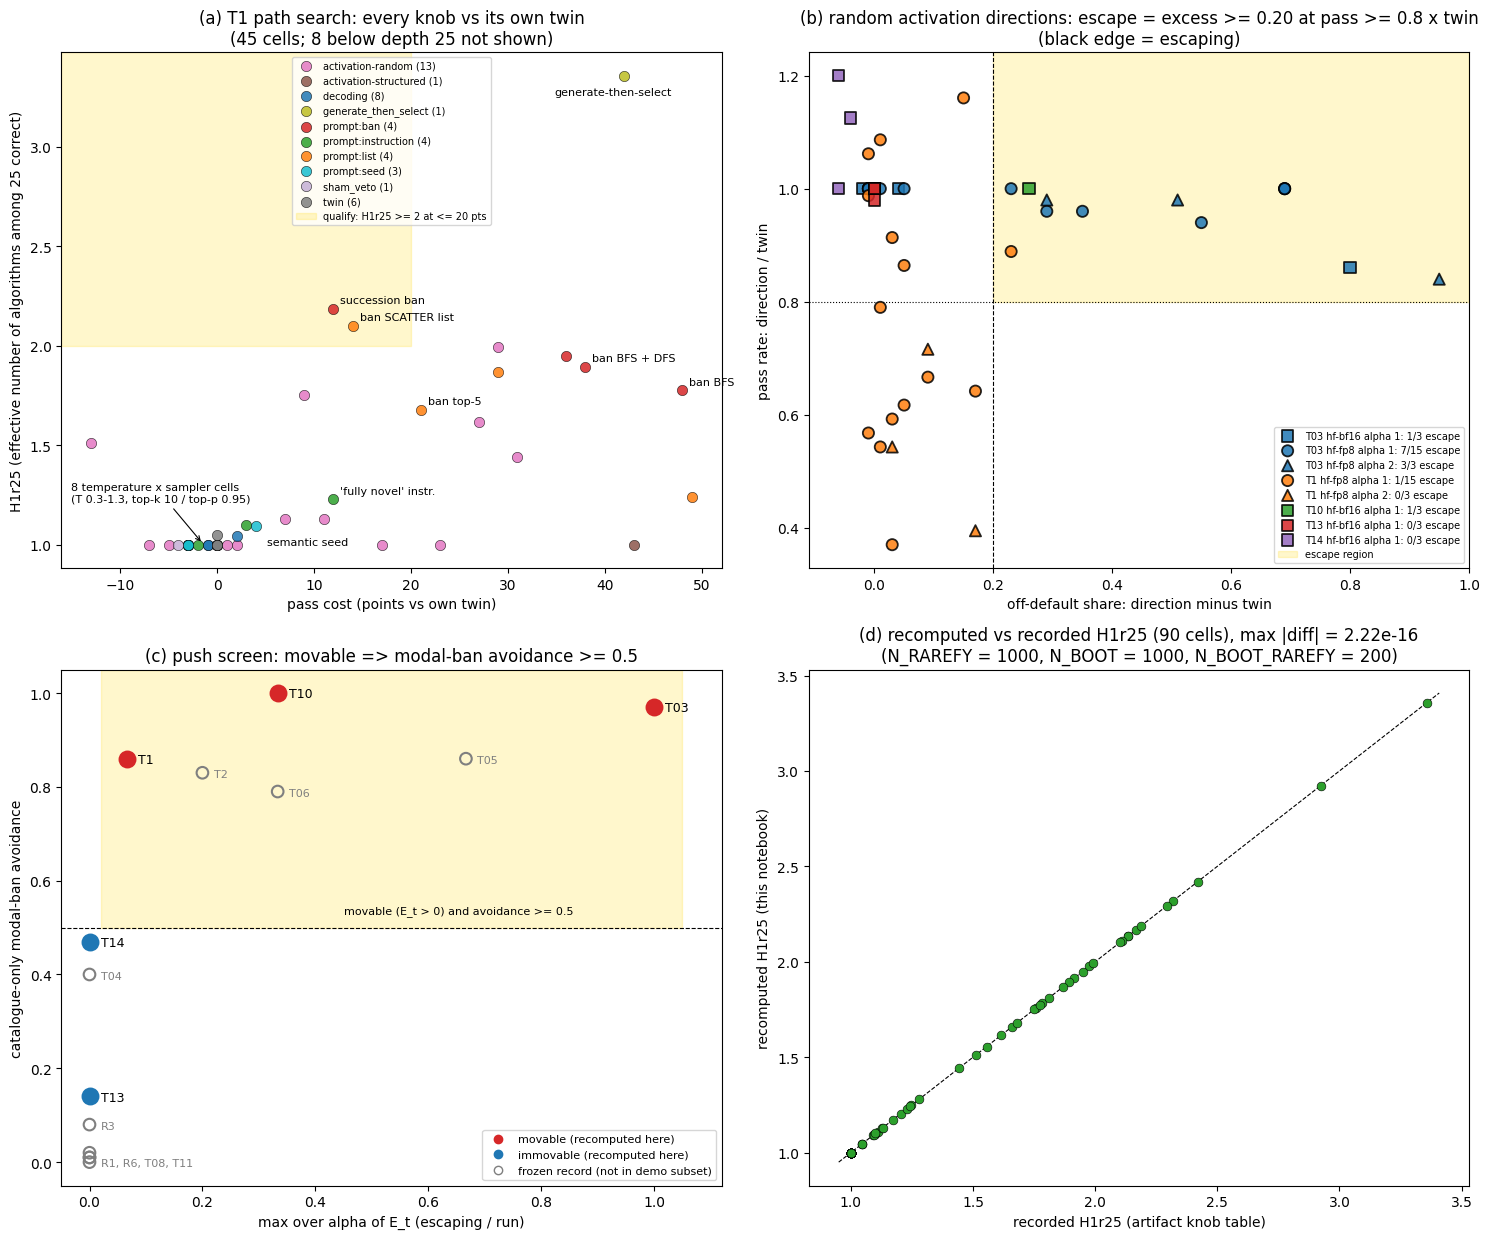

In [20]:
# (a) knob map of the path-search task T1, (b) escape geometry of the random directions, (c) the screen rule,
# (d) recomputed vs recorded Hill-1
FAM_COLORS = {"twin": "#7f7f7f", "mention_twin": "#bdbdbd", "sham_veto": "#c5b0d5", "decoding": "#1f77b4",
              "prompt:seed": "#17becf", "prompt:instruction": "#2ca02c", "prompt:novelty": "#98df8a",
              "prompt:nonce": "#ff9896", "prompt:ban": "#d62728", "prompt:list": "#ff7f0e", "veto": "#9467bd",
              "activation-random": "#e377c2", "activation-structured": "#8c564b", "activation-ban-derived": "#c49c94",
              "generate_then_select": "#bcbd22"}
# annotated T1 arms: label and text offset (points)
SHORT = {"A2:seed_semantic": ("semantic seed", (8, -14)), "A3:instr_fully_novel": ("'fully novel' instr.", (5, 4)),
         "A4s2:gen_then_select": ("generate-then-select", (-50, -14)), "single:bfs": ("ban BFS", (5, 4)),
         "multi:TOP5": ("ban top-5", (5, 4)), "multi:SCATTER": ("ban SCATTER list", (5, 4)),
         "succession:2": ("succession ban", (5, 4)), "two_step:TWO(bfs,dfs)": ("ban BFS + DFS", (5, 4))}
fig, axes = plt.subplots(2, 2, figsize=(15, 12.5))

# (a) every T1 cell with a depth-25 value: pass cost against the cell's own twin vs correct-only Hill-1
ax = axes[0, 0]
k1 = knob[(knob.task == "T1") & knob.H1r25.notna() & knob.pass_cost_pts.notna()]
if len(k1):
    for fam, g in k1.groupby("family"):
        ax.scatter(g.pass_cost_pts, g.H1r25, s=55, color=FAM_COLORS.get(fam, "k"), edgecolor="k", linewidth=0.4,
                   alpha=0.85, zorder=3, label=f"{fam} ({len(g)})")
    for _, r in k1[k1.arm.isin(list(SHORT))].iterrows():
        ax.annotate(SHORT[r.arm][0], (r.pass_cost_pts, r.H1r25), xytext=SHORT[r.arm][1], textcoords="offset points",
                    fontsize=8)
    dec = k1[k1.family == "decoding"]
    if len(dec):
        ax.annotate(f"{len(dec)} temperature x sampler cells\n(T 0.3-1.3, top-k 10 / top-p 0.95)",
                    (dec.pass_cost_pts.mean(), dec.H1r25.mean()), xytext=(-95, 30), textcoords="offset points",
                    fontsize=8, arrowprops={"arrowstyle": "->", "lw": 0.8})
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    ax.fill_between([x0, 20], 2, max(y1, 2.3), color="gold", alpha=0.2, zorder=1, label="qualify: H1r25 >= 2 at <= 20 pts")
    ax.set_xlim(x0, x1)
    ax.set_ylim(min(y0, 0.9), max(y1, 2.3))
    ax.legend(fontsize=7, loc="upper center")
else:
    ax.text(0.5, 0.5, f"no T1 cell among the first N_CELLS = {N_CELLS}", ha="center", transform=ax.transAxes)
n_below = int(((knob.task == "T1") & knob.H1r25.isna()).sum())
ax.set(xlabel="pass cost (points vs own twin)", ylabel="H1r25 (effective number of algorithms among 25 correct)",
       title=f"(a) T1 path search: every knob vs its own twin\n({len(k1)} cells; {n_below} below depth 25 not shown)")

# (b) each random direction x alpha: excess off-default share over its twin vs pass rate relative to the twin
ax = axes[0, 1]
dr = pd.DataFrame(extras["per_direction_rows"])
if len(dr):
    dr["excess"] = (1 - dr.n_default / dr.n_attempted) - (1 - dr.twin_n_default / dr.twin_n_attempted)
    dr["pass_ratio"] = (dr.n_passed / dr.n) / (dr.twin_n_passed / dr.twin_n)
    dr["escape"] = [escape_of(r)[0] for r in extras["per_direction_rows"]]
    tcol = dict(zip(sorted(dr.task.unique()), plt.cm.tab10.colors))
    mk = {("hf-fp8", 1.0): "o", ("hf-fp8", 2.0): "^", ("hf-bf16", 1.0): "s"}
    for (t, eng, a), g in dr.groupby(["task", "engine", "alpha"]):
        ax.scatter(g.excess, g.pass_ratio, s=65, marker=mk.get((eng, a), "D"), color=tcol[t],
                   edgecolors=["k" if e else "none" for e in g.escape], linewidths=1.3, alpha=0.85, zorder=3,
                   label=f"{t} {eng} alpha {a:g}: {int(g.escape.sum())}/{len(g)} escape")
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    ax.fill_between([0.20, max(x1, 0.3)], 0.8, max(y1, 1.05), color="gold", alpha=0.2, zorder=1, label="escape region")
    ax.axvline(0.20, color="k", ls="--", lw=0.8)
    ax.axhline(0.8, color="k", ls=":", lw=0.8)
    ax.set_xlim(x0, max(x1, 0.3))
    ax.set_ylim(y0, max(y1, 1.05))
    ax.legend(fontsize=7, loc="lower right")
ax.set(xlabel="off-default share: direction minus twin", ylabel="pass rate: direction / twin",
       title="(b) random activation directions: escape = excess >= 0.20 at pass >= 0.8 x twin\n(black edge = escaping)")

# (c) the screen rule: best escape fraction over alpha vs catalogue-only modal-ban avoidance, for all 14 tasks
ax = axes[1, 0]


def _emax(rec: dict) -> float:
    return max([v for v in (rec["alpha_1"]["E_t"], rec["alpha_2"]["E_t"]) if v is not None], default=0.0)


labels = {}
for t, rec in sorted(frozen["tasks"].items()):
    mine = t in screen["tasks"]
    rr = screen["tasks"][t] if mine else rec
    x, y = _emax(rr), rr["cat_only_ban_avoidance"]
    col = "#d62728" if rr["movable"] else "#1f77b4"
    ax.scatter(x, y, s=130 if mine else 70, color=col if mine else "none", edgecolor=col if mine else "#7f7f7f",
               linewidth=1.5, zorder=3)
    labels.setdefault((round(x / 0.04), round(y / 0.04)), []).append((t, mine, x, y))
for grp in labels.values():  # tasks at (nearly) the same point share one label
    mine = any(m for _, m, _, _ in grp)
    ax.annotate(", ".join(t for t, _, _, _ in grp), grp[0][2:], xytext=(8, -3), textcoords="offset points",
                fontsize=9 if mine else 8, color="k" if mine else "#7f7f7f")
ax.axhline(0.5, color="k", ls="--", lw=0.8)
ax.fill_between([0.02, 1.05], 0.5, 1.05, color="gold", alpha=0.2, zorder=1)
ax.text(0.45, 0.53, "movable (E_t > 0) and avoidance >= 0.5", fontsize=8)
ax.set_xlim(-0.05, 1.12)
ax.set_ylim(-0.05, 1.05)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="#d62728", label="movable (recomputed here)"),
                   Line2D([], [], marker="o", ls="", color="#1f77b4", label="immovable (recomputed here)"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec="#7f7f7f", label="frozen record (not in demo subset)")],
          fontsize=8, loc="lower right")
ax.set(xlabel="max over alpha of E_t (escaping / run)", ylabel="catalogue-only modal-ban avoidance",
       title="(c) push screen: movable => modal-ban avoidance >= 0.5")

# (d) reproduction check of the Monte-Carlo statistic
ax = axes[1, 1]
ok = np.isfinite(new.H1r25.values) & np.isfinite(old.H1r25.values)
if ok.any():
    ax.scatter(old.H1r25[ok], new.H1r25[ok], s=40, color="#2ca02c", edgecolor="k", linewidth=0.4, zorder=3)
    lo = float(min(old.H1r25[ok].min(), new.H1r25[ok].min())) - 0.05
    hi = float(max(old.H1r25[ok].max(), new.H1r25[ok].max())) + 0.05
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
    d = np.abs(new.H1r25[ok] - old.H1r25[ok])
    ax.set_title(f"(d) recomputed vs recorded H1r25 ({int(ok.sum())} cells), max |diff| = {d.max():.2e}\n"
                 f"(N_RAREFY = {N_RAREFY}, N_BOOT = {N_BOOT}, N_BOOT_RAREFY = {N_BOOT_RAREFY})")
ax.set(xlabel="recorded H1r25 (artifact knob table)", ylabel="recomputed H1r25 (this notebook)")
plt.tight_layout()
fig.savefig(WS / "figures" / "demo_summary.png", dpi=120, bbox_inches="tight")
plt.show()

## Summary

**What was reproduced.** With the original Monte-Carlo sizes, every one of the 99 demo cells matches the artifact's knob table on all 14 compared columns (largest difference 2.2e-16). The columns are Hill-1 and its CIs, coverage, pass cost with its Newcombe CI, off-default share, catalogue-only avoidance, and the escape and qualify flags. The five screened tasks reproduce their frozen `screen.json` records exactly: T03, T1 and T10 are movable, T13 and T14 are not. Substituting these records into the frozen file gives back the published sha256 `d6a2ca97…` byte for byte.

**What the path-search task T1 shows.** The model writes BFS. In the twins, 96 of 97 correct programs in exp6's T = 1.0 baseline are BFS, 81 of 81 in exp17's twin, and all 200 programs of exp4's baseline.
- *Temperature is not the creativity knob here.* Across T = 0.3–1.3 with top-k 10 or top-p 0.95, 7 of the 8 cells have Hill-1 = 1.00, the eighth reaches 1.04, and the off-default share stays at 0.01 or below. Sampling changes the wording, not the algorithm.
- *Context seeds and creativity instructions barely move it.* The entropy and word seeds give 1.00 and the semantic seed 1.09. The "creative" and "enumerate" instructions give 1.00, "new algorithm" 1.10, and "fully novel" 1.23 at a cost of 12 points. The 2,000-word "fully novel algorithm" instruction does move off BFS (off-default share 0.81), but only 28% of its programs pass, so it has no depth-25 value.
- *Bans move the algorithm, at a price.* Banning BFS by name sends 86% of programs off the default but costs 48 points (Hill-1 1.78). Banning the top-5 list gives 1.68 at 21 points. Only two T1 cells qualify, here and in the full 98-cell T1 table: the succession ban (2.19 at 12 points) and the SCATTER list ban (2.10 at 14 points). Generate-then-select reaches 3.36 at 42 points; it is a ceiling and is never ranked.
- *Activation directions depend on the task.* On T1, one of 15 random exp17 directions escapes at α = 1, towards DFS, and the decommitment steering direction at c = 0.25 costs 43 points with Hill-1 still 1.00. On T03, by contrast, 7 random direction-α cells qualify at a cost of 0–4 points (Hill-1 up to 2.92), above the modal ban (2.17 at 8 points).

**The screen.** On the five screened tasks, *movable* and *modal-ban avoidance ≥ 0.5* agree perfectly (a 3/0/0/2 table); on all 14 frozen tasks the table is 6/0/0/8 (one-sided Fisher p = 1/3003). This is a screen read off the same data, not a confirmation. The immovable side is also weakly tested: most tasks have K = 3 directions, which bounds the per-direction escape probability only below 0.54 (90% upper bound).

**Scaling.** The config cell already uses the original Monte-Carlo sizes. The knob stage takes about 3 s for the 99 cells, and the whole notebook runs in well under a minute once the packages are installed. The full 1,120-cell table and the other 12 stages need the 11 dependency artifacts. In the artifact's repository folder they run with `uv run eval.py --stages all` in about 1.5 minutes.